# Chromatic PSF from a field star

Fit a point source in wavelength bands, describe its chromatic shape with smooth trends, and save a compact reusable model. The supplied `data/fieldstar.fits` contains a real MUSE field-star cutout, including flux and variance. Identifying observation metadata and sky coordinates have been removed; spatial axes contain local angular offsets, with the pixel scale retained.

The aim is an accurate reconstruction in flux. Formal errors can be very small: reduced chi-square is a diagnostic, not a target for making the PSF arbitrarily complex.

In [1]:
%matplotlib inline

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from astropy import units as u
from astropy.modeling.models import Planar2D
from astropy.convolution import discretize_model
from astropy.visualization import ImageNormalize, AsinhStretch
from IPython.display import display

from prism.data import Cube
from prism.modeling.psf import fitimage, fitbands, fittrends, ChromaticPSF
from prism.modeling.models import MoffatPSF, EllipticalMoffatPSF

plt.rcParams['axes.xmargin'] = 0

In [2]:
cubepath = Path('data/fieldstar.fits')
outpath = Path('results/psf')
outpath.mkdir(parents=True, exist_ok=True)

cube = Cube.from_fits(cubepath, ext_values='DATA', ext_var='VAR', dtype=float)
print(cube.shape, cube.z[[0, -1]], cube.zunit)

# Apply any channel masks here: cube.mask uses True for valid samples.

(3681, 26, 26) [4750.2734375 9350.2734375] Angstrom


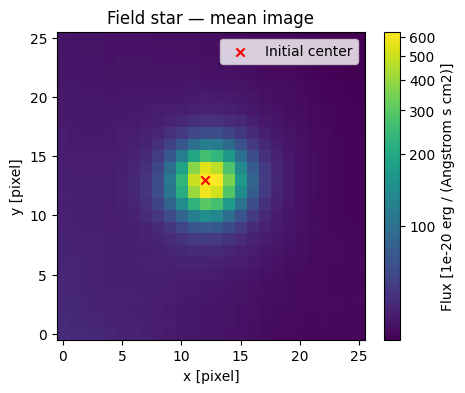

In [3]:
img = cube.get_image(method='mean')
ny, nx = img.shape
y, x = np.indices(img.shape)
cy, cx = np.unravel_index(np.nanargmax(img.values), img.shape)

fig, ax = plt.subplots(figsize=(5, 4))
norm = ImageNormalize(vmin=np.nanpercentile(img.values, 1),
                      vmax=np.nanpercentile(img.values, 99.8), stretch=AsinhStretch())
im = ax.imshow(img.values, origin='lower', norm=norm, cmap='viridis')
ax.scatter(cx, cy, color='red', marker='x', label='Initial center')
ax.set(xlabel='x [pixel]', ylabel='y [pixel]', title='Field star — mean image')
ax.legend()
fig.colorbar(im, ax=ax, label=f'Flux [{cube.unit}]')
plt.show()

## Profile and initialization

Prism provides ordinary Astropy `MoffatPSF` and `EllipticalMoffatPSF` models with fitted FWHM and `beta`, the wing exponent. `amplitude` is peak brightness. The ellipsoid uses two principal-axis widths and `theta` in radians; its profile remains centrosymmetric.

We initialize explicitly from the image peak and use `fitimage` on the mean image to seed all bands. Its default `init=None` preserves the supplied values; optional `init='peak'` seeds only free centroid/amplitude values within the selected pixels and parameter bounds. This helps maintain the same equivalent-axis convention. Near circularity the orientation is intrinsically weakly constrained; fixing `theta` is available when appropriate. `Planar2D` is a separate background and does not enter PSF normalization.

`factor` controls midpoint integration over each pixel. It does not resample the observations. Parameter `fixed` flags and bounds follow Astropy conventions.

In [4]:
model = EllipticalMoffatPSF(
    amplitude=float(img.values[cy, cx] - np.nanmedian(img.values)),
    x_0=float(cx), y_0=float(cy), fwhm_x=3.4, fwhm_y=3, beta=2.5, theta=0,
)
model.x_0.bounds = (cx - 3, cx + 3)
model.y_0.bounds = (cy - 3, cy + 3)
model.fwhm_x.bounds = (0.3, 12)
model.fwhm_y.bounds = (0.3, 12)
model.theta.bounds = (-np.pi/2, np.pi/2)
model.beta.bounds = (1.05, 12)
background = Planar2D(intercept=float(np.nanmedian(img.values)))
factor = 5

# One mean-image fit provides initial values for the independent band fits.
initial = fitimage(img, model, background=background, factor=factor)
assert initial['success'], initial['message']
model.parameters = np.array([initial[name] for name in model.param_names])
background.parameters = np.array([initial[name] for name in background.param_names])

In [5]:
bands = fitbands(cube, model, bands=20, background=background, factor=factor)
bands.meta['source'] = str(cubepath)

## Smooth trends and compact FITS model

With `basis='bspline'`, each dictionary value is the number of fitted coefficients; the local degree is at most cubic. Five coefficients have the same parameter budget as a polynomial of degree four. Interior knots are uniformly spaced and stored. Bounds on the coefficients keep the spline within the physical/user parameter bounds across its calibrated domain, without clipping predictions.

For comparison, `basis='polynomial'` uses the dictionary values as polynomial degrees. Up to four spline coefficients give a single polynomial segment; additional coefficients introduce local pieces. This improves locality but does not guarantee that every oscillation disappears. No automatic outlier rejection is used.

Select table rows explicitly before fitting if needed. Finite-field images retain their captured fraction of the infinite-plane PSF; they are not normalized again to sum to one. Formal local covariances are stored, but full trend uncertainty propagation is outside this example.

The spline domain reaches the outer calibrated channel limits, while measurements remain located at band centers. The fitted trend continues smoothly through the boundary half-bands, which are less constrained by measurements. Evaluation outside the calibrated domain still raises an error. Previously saved models retain their original constant padding.

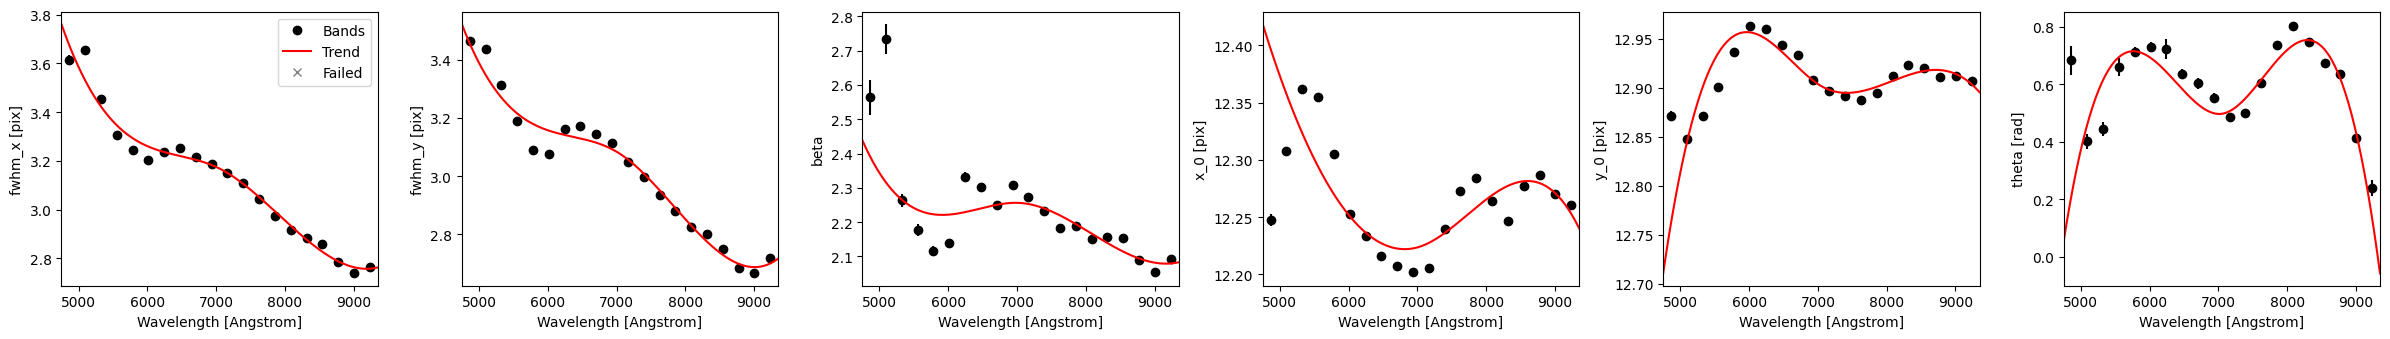

Spatial band fits: 20/20 converged


nband,wave,success,fwhm_x,fwhm_y,theta,beta,x_0,y_0,redchi2
,Angstrom,,pix,pix,rad,,pix,pix,
int64,float64,bool,float64,float64,float64,float64,float64,float64,float64
0,4864.648437499999,True,3.615301920634579,3.4626518260002834,0.6827047641242961,2.5640807768833005,12.247672455180751,12.871232697942428,4.971179488074317
1,5094.648437499999,True,3.65589029052061,3.436137927109845,0.4008913636546212,2.733161255512323,12.307897083099546,12.848136112173961,6.381123474269713
2,5324.648437499999,True,3.45479120824223,3.312229777149125,0.4429369666801293,2.2644609243327203,12.361893155405514,12.87122346581381,6.909658004614627
3,5554.648437499999,True,3.3074460047481535,3.1907459921891457,0.6597143201643801,2.177513985341657,12.355361073689037,12.900757247985348,7.461592593156245
4,5784.648437499999,True,3.2424848099861485,3.0910368832556023,0.7133853537768964,2.1168654707149486,12.305509829522704,12.93624188517609,9.563001325694929
5,6014.648437499999,True,3.203415352026078,3.0764051941894763,0.729388625243523,2.138255641133032,12.252758119287542,12.96338191719739,12.119246091301003
6,6244.648437499999,True,3.2362810866766223,3.1626332929971963,0.7235431172114576,2.3314967121273513,12.233194156290818,12.960112130552188,13.329448184740208
7,6474.648437499999,True,3.2535169798538295,3.173185607414592,0.6360863608380488,2.3016570581440323,12.216473226789807,12.944038665885614,19.856091934742015


In [6]:
trends = {'fwhm_x': 5, 'fwhm_y': 5, 'beta': 5, 'x_0': 5, 'y_0': 5, 'theta': 5}
basis = 'bspline'  # Counts coefficients; 5 matches the budget of polynomial degree 4.
psf = fittrends(bands, trends, basis=basis, display=True, save=outpath / 'fitted_parameters.pdf')
psf.write(outpath / 'psf.fits', overwrite=True)

# Results of the spatial fits in each band (success is their convergence flag).
print(f"Spatial band fits: {np.count_nonzero(psf.bands['success'])}/{len(psf.bands)} converged")
display(psf.bands[['nband', 'wave', 'success', 'fwhm_x', 'fwhm_y', 'theta', 'beta', 'x_0', 'y_0', 'redchi2']])

## Resolution versus wavelength

`psf.fwhm(wave)` returns the intrinsic principal-axis widths in `(x, y)` order, in pixels. The following conversion uses the square-pixel scale retained in the demonstration FITS header (`PIXSCALE`, arcseconds per pixel). Rotation does not change these intrinsic widths. The resolution curve is derived from the saved model rather than stored redundantly.

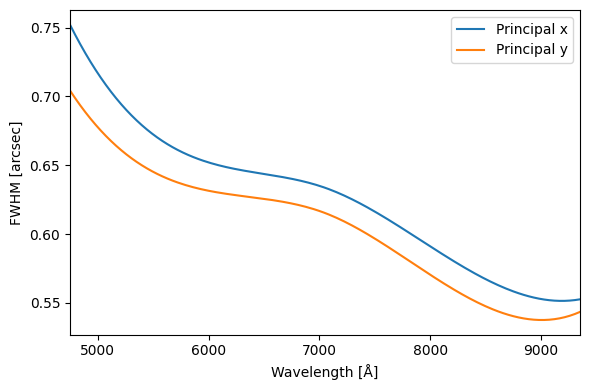

In [7]:
wave = np.linspace(*psf.domain, 200) * psf.unit
scale = cube.header['PRIMARY']['PIXSCALE'] * u.arcsec
widths = psf.fwhm(wave).to_value(u.pix) * scale

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(wave.to_value(u.AA), widths[:, 0].value, label='Principal x')
ax.plot(wave.to_value(u.AA), widths[:, 1].value, label='Principal y')
ax.set(xlabel='Wavelength [Å]', ylabel='FWHM [arcsec]')
ax.legend()
fig.tight_layout()
fig.savefig(outpath / 'resolution.pdf')
plt.show()

## Inspect one band

Change `band` below. This reconstructs the independent spatial fit, including the background, not the smoothed trend prediction. Data and model share a display scale. The absolute residual divided by the stellar peak is a useful first check of reconstruction quality; it does not by itself bound aperture-correction errors.

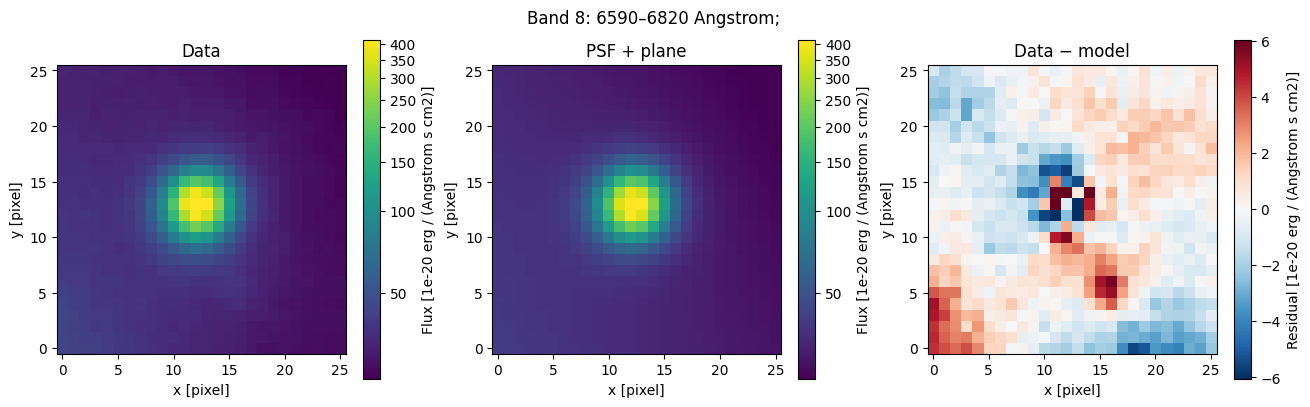

Peak absolute residual / fitted stellar peak: 4.532%


In [8]:
band = 8
assert bands['success'][band], bands['message'][band]

img = cube.get_image(weights=bands['channels'][band], method='mean')
fitted = model.copy()
for name in model.param_names:
    getattr(fitted, name).value = bands[name][band]
fitted_background = background.copy()
for name in background.param_names:
    getattr(fitted_background, name).value = bands[name][band]

# Astropy midpoint integration, matching factor used by fitbands.
fitted_image = discretize_model(fitted, x_range=(0, nx), y_range=(0, ny),
                               mode='oversample', factor=factor)
fitted_image += fitted_background(x, y)
residuals = np.where(img.mask, img.values - fitted_image, np.nan)

norm = ImageNormalize(vmin=np.nanpercentile(img.values, 1),
                      vmax=np.nanpercentile(img.values, 99.8), stretch=AsinhStretch())
limit = np.nanpercentile(np.abs(residuals), 99)
fig, axes = plt.subplots(1, 3, figsize=(13, 4), constrained_layout=True)
for ax, image, title in zip(axes[:2], [img.values, fitted_image], ['Data', 'PSF + plane']):
    im = ax.imshow(image, origin='lower', norm=norm, cmap='viridis')
    ax.set_title(title)
    fig.colorbar(im, ax=ax, label=f'Flux [{cube.unit}]')
im = axes[2].imshow(residuals, origin='lower', vmin=-limit, vmax=limit, cmap='RdBu_r')
axes[2].set_title('Data − model')
fig.colorbar(im, ax=axes[2], label=f'Residual [{cube.unit}]')
for ax in axes:
    ax.set(xlabel='x [pixel]', ylabel='y [pixel]')
fig.suptitle(f"Band {band}: {bands['lower'][band]:.0f}–{bands['upper'][band]:.0f} {cube.zunit}; "
             '')
fig.savefig(outpath / 'band-check.png', dpi=150)
plt.show()
print(f'Peak absolute residual / fitted stellar peak: '
      f'{np.nanmax(np.abs(residuals)) / np.max(fitted_image-fitted_background(x,y)):.3%}')

## Reload elsewhere

The input cube is not needed to reload the compact model. Retain the calibrated spatial pixel scale and wavelength convention; do not extrapolate outside `psf.domain`. The PSF corrects point-source aperture losses and does not separate unresolved host light.

In [9]:
# psf = ChromaticPSF.from_fits('results/psf/psf.fits')
# image = psf.get_image(6500 * u.AA, (26, 26), center=(13, 12))
# widths = psf.fwhm([5000, 6500, 8000] * u.AA)
# fraction = np.sum(image * aperture)  # Same pixel weights as spectrum extraction.
# psfcube = psf.get_cube(cube.z * cube.zunit, cube.shape[1:])